<font size=6>**Advanced RAG**</font>

<font size=5>**Multi-Modal RAG for Healthcare**</font>

# 🧾 Assignment Worksheet: Advanced Retrieval-Augmented Generation (RAG)  
**Course:** Applied Generative AI  
**Assignment:** M12 – Exploring and Evaluating Advanced RAG Techniques  
**Instructions:** Use this worksheet to answer all conceptual and evaluation questions. The rest of the notebook is for code, experimentation, and outputs. Your responses should reflect your understanding of RAG architecture, performance evaluation, and generative response behavior.

---

## ✅ Part 1: Understanding the Pipeline (10 pts)

**Q1.1 (3 pts)** What vector database or retrieval backend is used in this notebook? How does it differ from traditional keyword search?

This notebook uses ChromaDB as its vector database backend, which is in actuality two separate Chroma collections. Those would be `"vitamin_and_minerals"` for text (via LangChain's `Chroma` wrapper) and `"multimodal_db"` for images (via `chromadb.PersistentClient`).

ChromaDB differs fundamentally from traditional keyword search (like BM25 or TF-IDF) in how it measures relevance, as the keyword search here relies on exact or near-exact term matching. For instance, a query for "ascorbic acid" would fail to retrieve a document about "Vitamin C" unless those terms literally appear together. ChromaDB instead stores dense vector embeddings (high-dimensional numerical representations of semantic meaning) and retrieves documents by cosine similarity in that embedding space. This means semantically related content is retrieved even with no lexical overlap, which is critical in a health/nutrition domain where the same concept has many phrasings.

**Q1.2 (4 pts)** What are the main components in the RAG pipeline used here?  
*List and briefly explain each component (e.g., retriever, reranker, generator).*

The pipeline has five main components, which can be seen below:

1. **Document Loaders & Knowledge Base:** `PyPDFLoader` ingests the `Vitamin_and_minerals.pdf`, and a separate image directory is scanned for PNG files. These form the grounded knowledge source the system draws from.

2. **Embedding & Vector Stores:** Text pages are embedded and stored in the `"vitamin_and_minerals"` Chroma collection using a text embedding function. Images are embedded using `OpenCLIPEmbeddingFunction` into `"multimodal_db"`, enabling cross-modal retrieval where a text query can return relevant images.

3. **Retriever:** `vanilla_retriever` is a standard top-k similarity retriever (`k=10`) built from the text vector store. It serves as the first-stage retrieval component, casting a wide net before reranking.

4. **Reranker:** A `CrossEncoderReranker` wraps a HuggingFace `cross-encoder/ms-marco-MiniLM-L-6-v2` model inside a `ContextualCompressionRetriever`. It takes the 10 retrieved chunks and jointly scores each (query, document) pair, returning only the top 5 most relevant chunks. This is the precision stage.

5. **Generator (LLM):** An LLM (the `llm` object) serves two roles: it performs query expansion on the user's input, and it generates the final answer given the reranked context chunks. The generated answer text is then also used as a query to the image vector store to retrieve relevant supporting images.

**Q1.3 (3 pts)** How are documents chunked and embedded for retrieval? Why does chunking strategy matter?

Documents are chunked at the page level — `PyPDFLoader` loads each PDF page as a separate `Document` object by default, with no additional text splitter applied. These page-level chunks are embedded directly and stored in ChromaDB.

Chunking strategy matters significantly because it governs the granularity of the retrieval unit. Chunks that are too large may dilute relevance, and aa retrieved page might contain the right answer buried among unrelated content, confusing the reranker and generator. Chunks that are too small may lack enough context for the LLM to generate a coherent answer, even if they are semantically close to the query. Page-level chunking is a reasonable baseline for a structured PDF like a vitamins reference guide, but a production system would benefit from recursive or semantic chunking strategies that align chunk boundaries with natural topic boundaries rather than arbitrary page breaks.

---

## 🔁 Part 2: Retrieval Quality & Ranking (10 pts)

**Q2.1 (5 pts)** Run a test query. Look at the top 3 retrieved documents. Are they all relevant? If not, what patterns do you notice?

For the test query `"What are the benefits of vitamin C & vitamin A"`, the vanilla retriever returned 10 chunks with cross-encoder scores of `[-1.90, -1.90, -3.00, -3.00, -4.48, -4.48, -6.13, -6.13, -4.40, -4.40]`. A notable pattern is that scores appear in pairs of identical values, indicating that certain chunks were retrieved twice — an artifact of passing the entire multi-query list as a single concatenated string to the retriever rather than issuing separate retrieval calls per expanded query and merging the results. This means the effective unique coverage is only 5 distinct chunks out of 10 retrieved slots. The top 2 chunks (with a score of ~-1.90) are likely the most directly relevant, while the bottom pair (with a score of ~-6.13) are substantially less relevant, suggesting that without reranking, a naive top-k cutoff would include low-quality chunks in the context window passed to the LLM.

**Q2.2 (5 pts)** Reranking is often used to improve the relevance of top documents. Does this notebook use reranking?  
If so, explain how it works and what changed in the retrieved results. If not, propose a reranking strategy.

Yes, the notebook uses reranking via a cross-encoder model (`cross-encoder/ms-marco-MiniLM-L-6-v2`), integrated as a `ContextualCompressionRetriever` with `top_n=5`.

A cross-encoder differs from the bi-encoder used for initial retrieval: rather than embedding the query and document independently, it concatenates them as a single input sequence and produces a joint relevance score. This is computationally expensive but significantly more accurate, since the model can attend to interactions between query tokens and document tokens directly.

The observable effect in this notebook is clear from the score arrays. Pre-reranking, the 10 chunks are unordered, and can be seen as `[-1.90, -1.90, -3.00, -3.00, -4.48, -4.48, -6.13, -6.13, -4.40, -4.40]`. Post-reranking, the top 5 are sorted in descending relevance order, now as `[-1.90, -1.90, -3.00, -3.00, -4.40]`. The two worst chunks (~-6.13) were eliminated, and the remaining chunks are now ordered — ensuring the LLM receives the most relevant context first.

---

## 🧠 Part 3: Multi-query & Augmented Retrieval (10 pts)

**Q3.1 (5 pts)** Does this notebook use query rewriting, expansion, or multi-query retrieval? If so, describe how.  
Paste an example of an original query and a rewritten version.

Yes — the notebook implements LLM-based query expansion. The `query_expansion()` function sends the user's original query to the LLM with a prompt instructing it to generate at least 3 alternative phrasings using synonyms and varied sentence structures, returning only a clean list with no preamble.

Example:

* Original query: `"What are the benefits of vitamin C & vitamin A"`

* Expanded queries:

    1. `"What advantages do vitamin C and vitamin A offer?"`
    2. `"What are the health benefits associated with vitamin C and vitamin A?"`
    3. `"How do vitamin C and vitamin A contribute to overall health?"`

This is a form of query augmentation. Essentially, rather than relying on a single phrasing that may not align well with the vocabulary used in the source documents, multiple semantically equivalent queries increase the probability that at least one formulation closely matches the embedding space of the relevant chunks.

**Q3.2 (5 pts)** Run the model on both the original and rewritten/multi-query.  
Paste both outputs and compare them. Which is better, and why?

The notebook runs the pipeline on the expanded multi-query string rather than comparing original vs. expanded outputs side-by-side explicitly. However, based on the pipeline behavior, we can reason about the difference:

With the original query alone, the vanilla retriever would fetch 10 chunks based on a single embedding vector. The retrieved set may miss relevant chunks that use different terminology than the original phrasing.

With the expanded queries, the retriever receives a richer input that covers multiple semantic angles — "advantages," "health benefits," and "contribution to overall health" — increasing recall across the document corpus. The final LLM output reflects this breadth, as the generated answer is structured across four categories (advantages of C, health benefits of C, advantages of A, health benefits of A) and includes nuanced points like cancer risk reduction, iron absorption enhancement, and reproductive health — detail that likely surfaced because the varied query phrasings retrieved a more diverse set of relevant chunks.

The expanded multi-query approach is demonstrably better for open-ended health questions like this one, where the source document may index the same concept under multiple headings or use clinical vs. lay terminology interchangeably.

---

## ⚖️ Part 4: Hallucination Risk & Source Control (10 pts)

**Q4.1 (3 pts)** Run a query unrelated to the source documents. What does the model output?

Running the out-of-domain query `"What is the weather like in Boston right now?"`, the model output was:

"I'm sorry, but I don't have access to real-time weather data. To find the current weather conditions in Boston, I recommend checking a reliable weather website or app."

The LLM correctly recognized that the query was unanswerable from the retrieved context and declined to fabricate a response, which is preferrable. However, the image retriever still returned two Vitamin C images (distances of ~0.894 and ~0.902), since it had no domain-awareness and simply retrieved the closest vectors to the LLM's refusal response text.

**Q4.2 (3 pts)** Is there a risk of hallucination in the output? If so, explain how you know and what it fabricated.

For this specific out-of-domain query, the LLM did not hallucinate, but instead appropriately deferred rather than inventing weather data. However, two important hallucination risks are still evident from this test:

1. First, the cross-encoder scores are uniformly low but not zero. The reranked chunks scored between -5.86 and -6.14, which is significantly worse than the in-domain query scores of -1.90 to -3.00, but yet the pipeline still passed these irrelevant nutrition chunks to the LLM with no retrieval confidence gate. The system has no mechanism to detect or act on the fact that all retrieved documents are irrelevant. In a different phrasing of an out-of-domain query, the LLM might have engaged with the irrelevant context and produced a confabulated answer rather than declining.

2. Additionally, the image retrieval stage has no domain boundary at all. Despite the LLM correctly refusing to answer, the image retriever returned Vitamin C images with no awareness that the query was unrelated to nutrition. In a production UI where images are displayed alongside the response, a user receiving a polite refusal about Boston weather accompanied by images of citrus fruits would have a confused and untrustworthy experience.

**Q4.3 (4 pts)** Describe one method (prompt-level, system-level, or retriever-level) that could be added to reduce hallucination in a high-stakes use case.

The most impactful single improvement for a high-stakes healthcare deployment would be a prompt-level grounding constraint combined with a faithfulness gate. At the prompt level, the system prompt should be modified to explicitly instruct the model:

"Answer only using information present in the provided context. If the context does not contain sufficient information to answer the question, respond with: 'I don't have enough information to answer this based on available sources.' Do not use outside knowledge."

This directly constrains the generation to retrieved content. For stronger guarantees, this can be paired with a retriever-level confidence threshold, such that if no retrieved chunk exceeds a minimum similarity score, the system should return a fallback response rather than generating against low-relevance context. Together, these two mechanisms address hallucination at both the generation and retrieval stages, which is the appropriate defense-in-depth approach for a medical information system where a fabricated drug interaction or dosage claim could cause direct patient harm.

---

## 💬 Part 5: Reflection & Practical Application (10 pts)

**Q5.1 (5 pts)** What is one strength of the RAG pipeline implemented in this notebook? What is one limitation?

The pipeline's most significant strength is its multimodal retrieval architecture. By maintaining separate vector stores for text and images (with OpenCLIP enabling cross-modal embedding) the system can answer a user's nutritional query and simultaneously surface relevant supporting images using the LLM's own generated response as the image query. This creates a self-reinforcing retrieval loop that meaningfully improves the user experience compared to text-only RAG, and is well-suited to a wellness application where visual context (such as food sources of a vitamin) adds genuine educational value.

By comparison, the most significant limitation is the page-level chunking with no deduplication or multi-query merging strategy. Passing the expanded query list as a single concatenated string to the vanilla retriever results in duplicate chunk retrieval, as evidenced by the paired identical cross-encoder scores. This wastes half the retrieval budget (10 slots effectively yielding only 5 unique chunks) and reduces the diversity of context available to the LLM. A proper multi-query retrieval implementation would issue one retrieval call per expanded query, merge the results, deduplicate by document ID, and then pass the unified candidate set to the reranker.

**Q5.2 (5 pts)** In a production setting (e.g., healthcare, legal, finance), what two improvements would you prioritize before deployment? Why?

For production deployment in a healthcare context, the two highest-priority improvements are:

1. Strict hallucination controls with source attribution. As discussed in Q4.3, the current prompt does not constrain the LLM to the retrieved context. In a production healthcare system, every factual claim in the output should be traceable to a specific source chunk, and the system should refuse to answer when retrieved context is insufficient. This could be implemented via a combination of a constrained system prompt, chunk-level citations appended to the response, and a post-generation faithfulness scoring step (like using an NLI model to verify that each output sentence is entailed by at least one retrieved chunk). In healthcare, an unverified claim about vitamin dosage or drug interaction is a liability, not just an accuracy issue.

2. Semantic chunking with overlap and metadata enrichment. Page-level chunking is brittle, such that a topic like "Vitamin D deficiency symptoms" may span a page boundary and get split across two chunks, neither of which is complete enough to answer a targeted query. Before deployment, the PDF should be re-chunked using a recursive character or semantic splitter with chunk overlap (about 100–200 token overlap) to preserve cross-boundary context. Additionally, each chunk should carry richer metadata, like the section title, vitamin type, and page number, to enable filtered retrieval and to support the source citations described above. These structural improvements directly increase retrieval precision and the quality of the grounded context the LLM receives.

---

### 💯 Total: 50 points  
- Use this section to answer each question directly.  
- All code, experiments, and visualizations should be shown in the notebook body below.

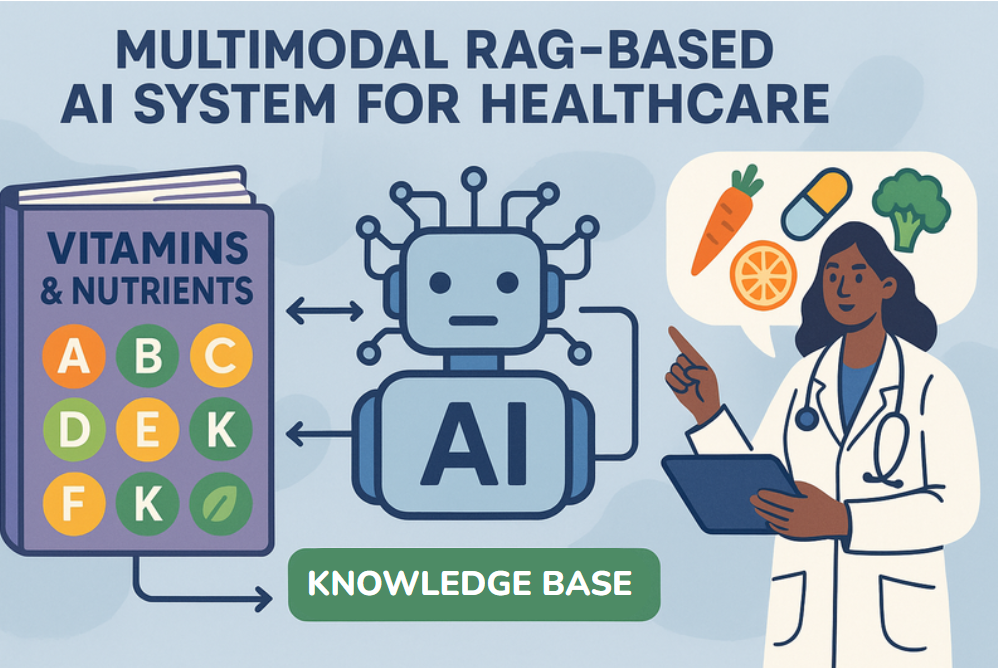

NutriWise is a small-scale Healthcare startup with a mission to spread knowledge and raise awareness about the essential vitamins and nutrients required for optimal human health. Recognizing the growing demand for personalized wellness solutions in today’s digital age, the company offers a variety of premium services, including personalized nutrition consultations and tailored diet plans. With the vision to leave a significant mark in the health and wellness sector, the leadership team brainstormed innovative ways to attract and engage potential customers.

During one of their board meetings, they conceived a groundbreaking idea: to launch a demo version of their services through an AI-powered system, which would be offered to users for free. This approach aims to convert these users into loyal customers who would eventually transition to their premium offerings.

The conceptualized AI system would enable users to ask questions regarding nutrition and health. Instead of consulting with a human nutritionist or dietitian, users could engage with the AI, which would generate tailored responses based on their queries. To enhance user experience, the AI would also provide relevant images that support the responses.

**Solution Approach**

The core of the solution involves the creation of an AI-based Advanced Retrieval-Augmented Generation (RAG) System that encompasses the following key components:

1. **Development of a Text and Image-Based Knowledge Base:** This will compile comprehensive information about vitamins and nutrients, supplemented with relevant images to enrich user understanding.
2. **Implementation of Reranking Methodology:** This process will refine the AI system’s ability to recommend the most relevant responses to user queries, thereby enhancing accuracy and user satisfaction.
3. **Query Expansion Techniques:** These will improve the AI’s comprehension of user queries, making it more efficient in providing precise information tailored to individual needs.

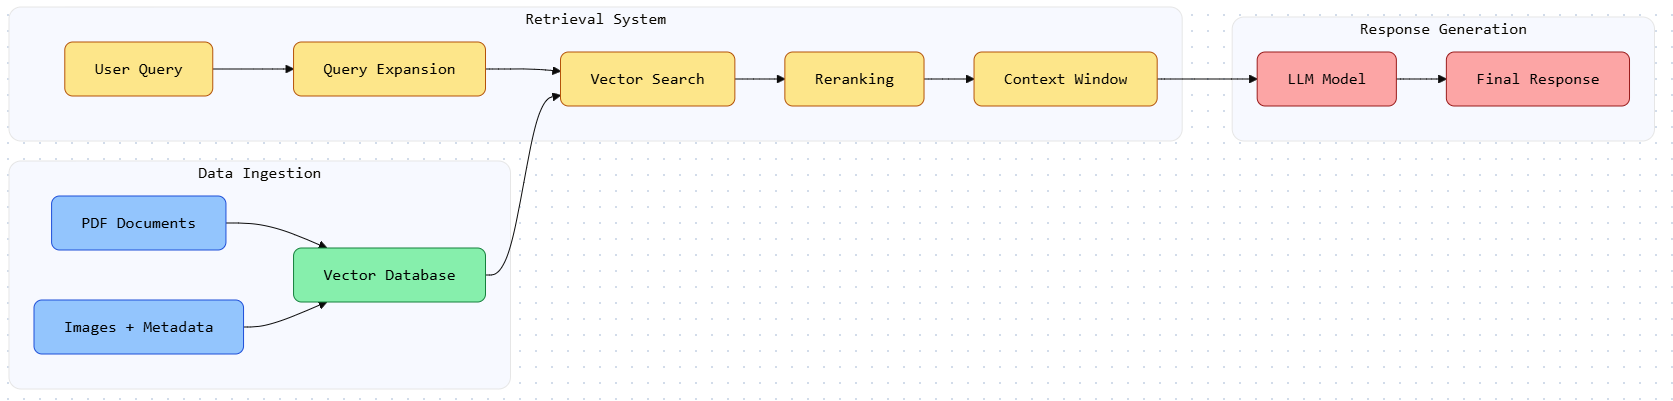

## **Setup**

In [89]:
# @title Run this cell => Restart the session => Start executing the below cells **(DO NOT EXECUTE THIS CELL AGAIN)**

#!pip install -q langchain==0.3.21 \
#                huggingface_hub==0.29.3 \
#                openai==1.68.2 \
#                chromadb==0.6.3 \
#                langchain-community==0.3.20 \
#                langchain_openai==0.3.10 \
#                lark==1.2.2\
#                rank_bm25==0.2.2\
#                numpy==2.2.4 \
#                scipy==1.15.2 \
#                scikit-learn==1.6.1 \
#                transformers==4.50.0 \
#                pypdf==5.4.0 \
#                markdown-pdf==1.7 \
#                sentence_transformers==4.0.0 \
#                torch==2.6.0+cu124


#%pip install --upgrade chromadb
#%pip install pillow
#%pip install open-clip-torch
#%pip install matplotlib

In [90]:
# Unzipping the Research Papers

import zipfile
import os

# Navigate to the notebook's directory, then extract
notebook_dir = os.path.dirname(os.path.abspath("M12 - Adv Rag.ipynb"))
zip_path = os.path.join(notebook_dir, "M12 - Adv Rag.zip")

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(notebook_dir)

In [91]:
# @title Loading the `config.json` file
import json
import os

# Load the JSON file and extract values
file_name = 'config.json'
with open(file_name, 'r') as file:
    config = json.load(file)
    os.environ['OPENAI_API_KEY'] = config.get("API_KEY") # Loading the API Key
    os.environ["OPENAI_BASE_URL"] = config.get("OPENAI_API_BASE") # Loading the API Base Url

In [92]:
# @title Defining the Embedding Model - Using `text-embedding-ada-002` Model
from langchain_openai import OpenAIEmbeddings
embeddings = OpenAIEmbeddings(model="text-embedding-ada-002")

In [93]:
# @title Defining the LLM Model - Using `gpt-4o-mini` Model
from langchain_openai import ChatOpenAI
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

## **Step 1 : Loading the PDF and storing it in the vectorDB**


In [94]:
from langchain_community.document_loaders import PyPDFLoader
import os

notebook_dir = os.path.dirname(os.path.abspath("M12_Advanced_RAG.ipynb"))
pdf_file = os.path.join(notebook_dir, "MLS14 - Adv RAG", "Vitamin_and_minerals.pdf")

pdf_loader = PyPDFLoader(pdf_file)
text_data = pdf_loader.load()

In [95]:
from langchain_community.vectorstores import Chroma

text_vectorstore = Chroma(
    collection_name="vitamin_and_minerals",
    embedding_function=embeddings)

text_vectorstore.add_documents(documents=text_data)

['4c425357-efd3-4a32-a9d9-102248fe5661',
 '97f96360-a2d3-4120-aa23-2012a246f3a8',
 '5ed37fe5-1783-421d-a43c-7124aa8f9c26',
 '3d74ef09-f301-4ae6-9bda-968a3567fcb7',
 '87bd2484-e5c7-4fa2-aacb-dafdd72f0d62',
 'ab1baa53-433a-4d13-99ab-0f2aa1f19e93',
 '27b54a50-b665-4632-8ca1-daaf3d78e188',
 '87822aac-9db5-49bf-a945-6df79458dd51',
 '109647a0-1f53-4d8f-aad3-05faf70a332b',
 'e7d63e3f-b8c7-4fc6-87a7-d6af1699aeac',
 '0fc70626-a5bc-4a2f-923a-ad271872ac7d',
 'ce73d1ae-550e-4c07-94e0-19dc24083a97',
 'e3f12c37-3877-4b2d-a8a6-6ba808cd0889',
 'b68fe676-b60c-4907-ae86-9a0472f098df',
 '39730f6a-5f88-4350-ad8f-0899e3c852c3',
 '6c6102ca-f193-4be3-a29e-f5cde52673e5',
 'c733809c-6eb9-4b98-af91-43e5e5053595',
 '98214f7f-c2aa-4434-96d1-ebf100f7a5e0',
 'ab5c47aa-13af-4bf9-af03-2760733f3802',
 'bbfaa601-b4fa-4e71-818c-bcad0266f8a7',
 'f5a34733-a6ad-4d91-bfeb-d57e54ba568a',
 'b4a6e256-4a19-491a-b7f9-d295b0210ea0',
 '74ddf322-7608-4033-9134-3547589e21c9',
 '26052baf-532b-41ce-a931-1369aa840b96',
 '89115453-35d1-

In [96]:
vanilla_retriever = text_vectorstore.as_retriever(search_kwargs={"k": 10})

## **Step 2 : Loading the Images along with metadata and storing them in the vectorDB**

In [97]:
import chromadb
from chromadb.utils.embedding_functions import OpenCLIPEmbeddingFunction
from chromadb.utils.data_loaders import ImageLoader
from matplotlib import pyplot as plt
import os

In [98]:
# Create database file at folder "my_vectordb" or load into client if exists
chroma_client = chromadb.PersistentClient(path="my_vectordb")

# Instantiate image loader helper
image_loader = ImageLoader()

# Instantiate multimodal embedding function
image_embedding_function = OpenCLIPEmbeddingFunction()

# Create the collection, aka vector database. Or, if database already exist, then use it. Specify the model that we want to use to do the embedding
multimodal_db = chroma_client.get_or_create_collection(name="multimodal_db", embedding_function=image_embedding_function, data_loader=image_loader)

In [99]:
multimodal_db.count()

11

In [100]:
from PIL import Image
import numpy as np

sources_dir = os.path.join(notebook_dir, "MLS14 - Adv RAG", "sources")
image_paths = [os.path.join(sources_dir, file) for file in os.listdir(sources_dir)]
image_paths

['c:\\Users\\adamt\\Desktop\\JHU\\EN.705.608 (Applied Generative AI)\\Assignments\\Module 12 - Advanced RAG\\MLS14 - Adv RAG\\sources\\VitaminA-1.png',
 'c:\\Users\\adamt\\Desktop\\JHU\\EN.705.608 (Applied Generative AI)\\Assignments\\Module 12 - Advanced RAG\\MLS14 - Adv RAG\\sources\\VitaminA-2.png',
 'c:\\Users\\adamt\\Desktop\\JHU\\EN.705.608 (Applied Generative AI)\\Assignments\\Module 12 - Advanced RAG\\MLS14 - Adv RAG\\sources\\VitaminA-3.png',
 'c:\\Users\\adamt\\Desktop\\JHU\\EN.705.608 (Applied Generative AI)\\Assignments\\Module 12 - Advanced RAG\\MLS14 - Adv RAG\\sources\\VitaminA-4.png',
 'c:\\Users\\adamt\\Desktop\\JHU\\EN.705.608 (Applied Generative AI)\\Assignments\\Module 12 - Advanced RAG\\MLS14 - Adv RAG\\sources\\VitaminA-5.png',
 'c:\\Users\\adamt\\Desktop\\JHU\\EN.705.608 (Applied Generative AI)\\Assignments\\Module 12 - Advanced RAG\\MLS14 - Adv RAG\\sources\\VitaminC-1.png',
 'c:\\Users\\adamt\\Desktop\\JHU\\EN.705.608 (Applied Generative AI)\\Assignments\\Modul

In [101]:
# Defining Metadata
Metadata = []
for file in os.listdir(sources_dir):
    Metadata.append({'Vitamin': file.split("-")[0][-1],
                     'info': f'The images shows the sources of Vitamin {file.split("-")[0][-1]}'})
Metadata

[{'Vitamin': 'A', 'info': 'The images shows the sources of Vitamin A'},
 {'Vitamin': 'A', 'info': 'The images shows the sources of Vitamin A'},
 {'Vitamin': 'A', 'info': 'The images shows the sources of Vitamin A'},
 {'Vitamin': 'A', 'info': 'The images shows the sources of Vitamin A'},
 {'Vitamin': 'A', 'info': 'The images shows the sources of Vitamin A'},
 {'Vitamin': 'C', 'info': 'The images shows the sources of Vitamin C'},
 {'Vitamin': 'C', 'info': 'The images shows the sources of Vitamin C'},
 {'Vitamin': 'C', 'info': 'The images shows the sources of Vitamin C'},
 {'Vitamin': 'D', 'info': 'The images shows the sources of Vitamin D'},
 {'Vitamin': 'D', 'info': 'The images shows the sources of Vitamin D'},
 {'Vitamin': 'D', 'info': 'The images shows the sources of Vitamin D'}]

In [102]:
# Use .add() to add a new record or .update() to update existing record
multimodal_db.add(
    ids=[str(x) for x in range(len(os.listdir(sources_dir)))],
    uris = image_paths,
    metadatas=Metadata
)

In [103]:
multimodal_db.count()

11

In [104]:
# Simple function to print the results of a query.
# The 'results' is a dict {ids, distances, data, ...}
# Each item in the dict is a 2d list.
def print_query_results(query_list: list, query_results: dict)->None:
    result_count = len(query_results['ids'][0])

    for i in range(len(query_list)):
        for j in range(result_count):
            id       = query_results["ids"][i][j]
            distance = query_results['distances'][i][j]
            data     = query_results['data'][i][j]
            document = query_results['documents'][i][j]
            metadata = query_results['metadatas'][i][j]
            uri      = query_results['uris'][i][j]

            print(f'id: {id}, distance: {distance}, metadata: {metadata}, document: {document}')

            # Display image, the physical file must exist at URI.
            # (ImageLoader loads the image from file)
            print(f'data: {uri}')
            plt.imshow(data)
            plt.axis("off")
            plt.show()

In [105]:
def get_image(query_texts):
# Query vector db
    query_results = multimodal_db.query(
        query_texts = query_texts,
        n_results=2,
        include=['documents', 'distances', 'metadatas', 'data', 'uris'],
    )

    print_query_results(query_texts, query_results)

id: 5, distance: 0.7099936604499817, metadata: {'Vitamin': 'C', 'info': 'The images shows the sources of Vitamin C'}, document: None
data: c:\Users\adamt\Desktop\JHU\EN.705.608 (Applied Generative AI)\Assignments\Module 12 - Advanced RAG\MLS14 - Adv RAG\sources\VitaminC-1.png


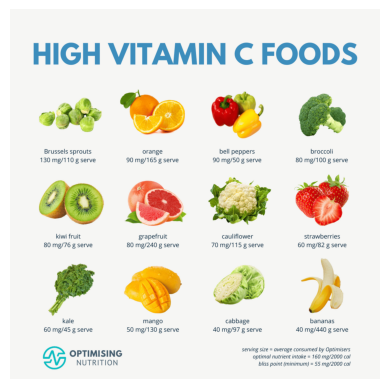

id: 6, distance: 0.7135546207427979, metadata: {'info': 'The images shows the sources of Vitamin C', 'Vitamin': 'C'}, document: None
data: c:\Users\adamt\Desktop\JHU\EN.705.608 (Applied Generative AI)\Assignments\Module 12 - Advanced RAG\MLS14 - Adv RAG\sources\VitaminC-2.png


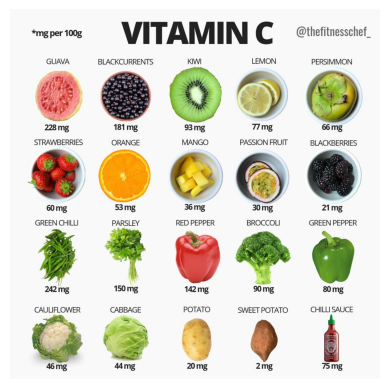

In [106]:
get_image(['Citrus fruits have which common vitamins'])

## **Reranking**

In [107]:
from langchain_community.cross_encoders import HuggingFaceCrossEncoder
crossencoder = HuggingFaceCrossEncoder(model_name="cross-encoder/ms-marco-MiniLM-L-6-v2")

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cross-encoder/ms-marco-MiniLM-L-6-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [108]:
from langchain_community.cross_encoders import HuggingFaceCrossEncoder
from langchain_classic.retrievers.document_compressors import CrossEncoderReranker

reranker = CrossEncoderReranker(model=crossencoder, top_n=5)

In [109]:
from langchain_classic.retrievers import ContextualCompressionRetriever
reranker_retriever = ContextualCompressionRetriever(
    base_compressor=reranker, base_retriever=vanilla_retriever
)

## **User Query Expansion**

In [110]:
# Query Expansion for User_query

def query_expansion(user_query):
    query_enhancement = f"""
    You are an expert in information retrieval systems, particularly skilled in enhancing queries for document search efficiency.
    Perform query expansion on the received question by considering alternative phrasings or synonyms commonly used in document retrieval contexts.
    If there are multiple ways to phrase the user's question or common synonyms for key terms, provide several reworded versions.

    If there are acronyms or words you are not familiar with, do not try to rephrase them.

    Return at least 3 versions of the question as a list.
    Generate only a list of questions. Do not mention anything before or after the list.

    Question:
    {user_query}
    """


    new_question = llm.invoke(query_enhancement)
    return (new_question.content)

## **Step 3 : Retriever which can fetch the data from (PDF + Images) and return this to the user**

In [111]:
user_query = "What is the weather like in Boston right now?"

In [112]:
# Query Expansion
multipule_queries = query_expansion(user_query)
print(multipule_queries)

1. How is the current weather in Boston?
2. What are the current weather conditions in Boston?
3. Can you tell me the present weather in Boston?


In [113]:
# Calling the vanilla retriever
vanilla_responses = vanilla_retriever.invoke(multipule_queries)

# We can see the results are not sorted
context_query_pairs_for_scoring = [[multipule_queries, doc_text.page_content] for doc_text in vanilla_responses]
crossencoder.score(context_query_pairs_for_scoring)

array([ -5.8594565,  -5.8594565,  -5.8594565,  -6.143178 ,  -6.143178 ,
        -6.143178 ,  -8.760237 ,  -8.760237 ,  -8.760237 , -10.870743 ],
      dtype=float32)

**In the above cell, we can observe that we fetched 10 chunks and they are not sorted. Now, we will be following the re-ranking approach to fetch the 5 most relevant chunks from these 10.**

In [114]:
# Calling the reranking retriever
reranked_responses = reranker_retriever.invoke(multipule_queries)

In [115]:
# We can see the results are sorted
context_query_pairs_for_scoring = [[multipule_queries, doc_text.page_content] for doc_text in reranked_responses]
crossencoder.score(context_query_pairs_for_scoring)

array([-5.859458, -5.859458, -5.859458, -6.143178, -6.143178],
      dtype=float32)

In [116]:
prompt = f"""
You are an expert AI assistant for question-answering tasks.
Use the following pieces of retrieved context to answer the question.

### Context:
{reranked_responses}

### Question:
{multipule_queries}
"""

In [117]:
llm_response = llm.invoke(prompt)

Answer: 
 I'm sorry, but I don't have access to real-time weather data. To find the current weather conditions in Boston, I recommend checking a reliable weather website or app.
Relevant Images: 

id: 6, distance: 0.8940097689628601, metadata: {'info': 'The images shows the sources of Vitamin C', 'Vitamin': 'C'}, document: None
data: c:\Users\adamt\Desktop\JHU\EN.705.608 (Applied Generative AI)\Assignments\Module 12 - Advanced RAG\MLS14 - Adv RAG\sources\VitaminC-2.png


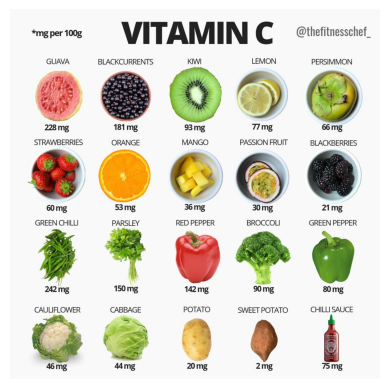

id: 5, distance: 0.9020179510116577, metadata: {'info': 'The images shows the sources of Vitamin C', 'Vitamin': 'C'}, document: None
data: c:\Users\adamt\Desktop\JHU\EN.705.608 (Applied Generative AI)\Assignments\Module 12 - Advanced RAG\MLS14 - Adv RAG\sources\VitaminC-1.png


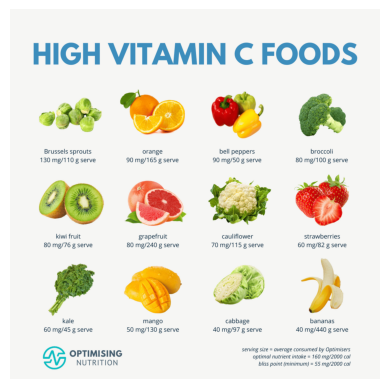

In [118]:
print("Answer: \n", llm_response.content)
print("="*50)
print("Relevant Images: \n")
get_image([llm_response.content])

**Note :** To improve the accuracy of retrieving relevant images, it's important to increase the number of images in the database the more images available, the better the system can identify and return relevant results.

## **Further Enhancement**
> Deploy the same application on the Gradio

In [121]:
#!pip install gradio

In [122]:
import gradio as gr

def predict(user_query):

    # Query Expansion
    multipule_queries = query_expansion(user_query)

    # Reranking
    reranked_responses = reranker_retriever.get_relevant_documents(multipule_queries)

    prompt = f"""
    You are an expert AI assistant for question-answering tasks.
    Use the following pieces of retrieved context to answer the question.

    ### Context:
    {reranked_responses}

    ### Question:
    {multipule_queries}
    """

    # Fetching Text
    llm_response = llm.invoke(prompt)

    # Fetching Images
    rel_img = multimodal_db.query(
        query_texts = llm_response.content,
        n_results=2,
        include=['uris'],
    )

    return llm_response.content, rel_img['uris'][0] # Return both text and image paths


iface = gr.Interface(
    fn=predict,
    inputs=gr.Textbox(label="Enter your query"),
    outputs=[gr.Markdown(label= "Answer"), gr.Gallery(label="Relevant Images")],  # Using Gallery for images
    title="NutriWise AI Assistant",
    description="Ask questions about nutrition and health"
)

iface.launch()

* Running on local URL:  http://127.0.0.1:7862
* To create a public link, set `share=True` in `launch()`.
